In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ai4_tools as ai4
import os

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, learning_curve, train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=UserWarning)
RUNTIME = ai4.show_runtime()

Runtime: Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz (2 cores, 12.7 GB) | CPU only | Python 3.13.18


### Data

In [ ]:
# Loading the dataset
MY_FILE = "stroke-prediction.csv"   # your file name, as a string

if not os.path.exists(MY_FILE):   # Colab: pick the file in the upload dialog
    from google.colab import files
    files.upload()

raw = pd.read_csv(MY_FILE)
print(raw.shape)
raw.head()

(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
# Target and ID removal
TARGET = "stroke"   # the column you predict, as a string (see the data sheet)
DROP = ["id"]   # columns the model must not see, or [] if none (Tutorial 1, section 2)

df = raw.drop(columns=DROP)

# A column with a different value on every row only labels the row: it cannot generalise.
labels = [c for c in df.columns if c != TARGET and df[c].nunique() == len(df)]
ai4.check("1.1 the target is a column", TARGET in df.columns, "check the spelling against the data sheet")
ai4.check("1.2 no ID column left", not labels, "{} has a different value on every row: add it to DROP".format(labels))

PASS  1.1 the target is a column
PASS  1.2 no ID column left


True

### Exploration and cleaning

In [ ]:
# Data Overview
# One row per column: its type, missing values, distinct values, and the range of the numbers.
def overview(d):
    numbers = d.select_dtypes("number")
    return pd.DataFrame({"type": d.dtypes.astype(str), "missing": d.isna().sum(),
                         "distinct": d.nunique(), "min": numbers.min(), "max": numbers.max()})

overview(df)

,type,missing,distinct,min,max
age,float64,0,104,0.08,82.00
avg_glucose_level,float64,0,3979,55.12,271.74
bmi,float64,201,418,10.30,97.60
ever_married,object,0,2,NaN,NaN
gender,object,0,3,NaN,NaN
heart_disease,int64,0,2,0.00,1.00
hypertension,int64,0,2,0.00,1.00
residence_type,object,0,2,NaN,NaN
smoking_status,object,0,4,NaN,NaN
stroke,int64,0,2,0.00,1.00


In [ ]:
# No additional cleaning is needed
# Because we want to avoid removing valid patient records or making assumptions about BMI measurements without enough evidence

In [ ]:
# Remove any target missing-value and Check data
df = df.dropna(subset=[TARGET])   # a row without a target cannot be used
# Check whether any rows that have numbers are not accidentally stored as text
text_numbers = [c for c in df.columns if c != TARGET and df[c].dtype == object and df[c].nunique() > 20]
ai4.check("2.1 no numbers stored as text", not text_numbers,
          "{} is text with many distinct values: convert it in the cell above".format(text_numbers))
# Display the updated dataset summary
overview(df)

PASS  2.1 no numbers stored as text


,type,missing,distinct,min,max
age,float64,0,104,0.08,82.00
avg_glucose_level,float64,0,3979,55.12,271.74
bmi,float64,201,418,10.30,97.60
ever_married,object,0,2,NaN,NaN
gender,object,0,3,NaN,NaN
heart_disease,int64,0,2,0.00,1.00
hypertension,int64,0,2,0.00,1.00
residence_type,object,0,2,NaN,NaN
smoking_status,object,0,4,NaN,NaN
stroke,int64,0,2,0.00,1.00


###Class balance

In [ ]:
# The share of each class: what would always predicting the commonest one score?
df[TARGET].value_counts(normalize=True)
# This is very useful because stroke is an imbalanced dataset with a 95.1% no stroke proportion
# This is why we use ROC AUC as our primary metric and recall as secondary, because accuracy alone would not be enough
# Because if the model assumed no stroke for all cases it would be 95.1% accurate even though it missed alot of strokes!!

,proportion
stroke,
0,0.951272
1,0.048728


### Split

In [ ]:
# Define X and y from the stroke dataset
y = df[TARGET]
X = df.drop(columns=[TARGET])

# Splitting training and test data
# 80% to train, 20% to test. What keeps the class shares the same in both? (Tutorial 1, section 2)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

shares = pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)})
ai4.check("3.1 the split is stratified", (shares["train"] - shares["test"]).abs().max() < 0.01,
          "the class shares differ between the two parts: see the comment above the split")
shares.round(3)

PASS  3.1 the split is stratified


,train,test
stroke,,
0,0.951,0.951
1,0.049,0.049


###Baseline

In [ ]:

# As in Tutorial 1, with one addition: imputers fill missing values, learning from the
# training rows only. Numbers: median. Text: commonest value, then one-hot.
numeric_cols = X.select_dtypes("number").columns.tolist()
text_cols = [c for c in X.columns if c not in numeric_cols]
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median"))]), numeric_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), text_cols),
])
pipe = Pipeline([("prep", preprocess), ("model", GradientBoostingClassifier(loss='log_loss', learning_rate=0.1, n_estimators=100, max_depth=3, random_state=0))])

# keep the test set untouched until we fit and evaluate through cross-validation
# We want the median to be learned form the training data inside the pipeline only, not from the entire dataset
# This is important to prevent data leakage inside during cross-validation
#pipe.fit(X_train, y_train)
#pred = pipe.predict(X_test)

# No "StandardScaler" used here. Whilst it is beneficial for LogisticRegression because it uses coefficients in its optimisation, gradient boosting uses decision trees, which do not require scaling, becuase they split values based on thresholds
# For missing numerical values, median imputation will be used because the median is less affected to data outliers than the mean

### Cross-Validation & Model Performance

In [ ]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
# Training and validation ROC AUC, and recall for each fold
# Fit time and scoring time for each fold
# Fit time is the time taken to train the pipeline on each fold
# Scoring time is the time taken to test the trained model and calculate its acccuracy and evaluation metrics like ROC AUC and recall
s = cross_validate(
    pipe,
    X_train,
    y_train,
    cv=cv,
    scoring=["roc_auc", "recall"],
    return_train_score=True
)

In [ ]:
s


{'fit_time': array([1.32960129, 1.26661897, 1.22931266, 1.32217741, 1.35172248]),
 'score_time': array([0.04686117, 0.06623054, 0.04041457, 0.04443336, 0.09105325]),
 'test_roc_auc': array([0.83296915, 0.81616324, 0.86131105, 0.86070463, 0.87110682]),
 'train_roc_auc': array([0.95160002, 0.94641352, 0.95438382, 0.95335905, 0.95281301]),
 'test_recall': array([0.  , 0.05, 0.05, 0.  , 0.1 ]),
 'train_recall': array([0.2327044 , 0.20754717, 0.2327044 , 0.225     , 0.20754717])}

### Experiment: Compare 30 trees vs 100 trees vs 1000 trees

---



In [ ]:
 experiments = {
    "baseline (100 trees)": pipe,

    "fewer estimators (30 trees)": Pipeline([("prep", preprocess), ("model", GradientBoostingClassifier(loss='log_loss', learning_rate=0.1, n_estimators=30, max_depth=3, random_state=0))]),

    "more estimators (1000 trees)": Pipeline([("prep", preprocess), ("model", GradientBoostingClassifier(loss='log_loss', learning_rate=0.1, n_estimators=1000, max_depth=3, random_state=0))]),
}

rows = []
for name, candidate in experiments.items():
    s = cross_validate(candidate, X_train, y_train, cv=cv, scoring=["roc_auc", "recall"], return_train_score = True)

    rows.append({"experiment": name,
                 "training ROC AUC": s["train_roc_auc"].mean(),
                 "validation ROC AUC": s["test_roc_auc"].mean(),
                 "ROC AUC spread": s["test_roc_auc"].std(),
                 "training recall": s["train_recall"].mean(),
                 "validation recall": s["test_recall"].mean(),
                 "fit time (s)": s["fit_time"].mean()})

ai4.check("6.1 at least one experiment besides the baseline", len(experiments) >= 2,
          "add a variant to the dictionary above")
pd.DataFrame(rows).round(4)


PASS  6.1 at least one experiment besides the baseline


,experiment,training ROC AUC,validation ROC AUC,ROC AUC spread,training recall,validation recall,fit time (s)
0,baseline (100 trees),0.9517,0.8485,0.0205,0.2211,0.0400,1.5895
1,fewer estimators (30 trees),0.9107,0.8542,0.0228,0.0540,0.0050,0.2816
2,more estimators (1000 trees),1.0000,0.7956,0.0295,0.9987,0.0854,6.7799


### Experiment: Compare Max depth = 1, 2, 3

---



In [ ]:
 experiments = {
    "baseline (depth 3)":  Pipeline([("prep", preprocess), ("model", GradientBoostingClassifier(loss='log_loss', learning_rate=0.1, n_estimators=30, max_depth=3, random_state=0))]),

    "very simple trees  (depth 1)": Pipeline([("prep", preprocess), ("model", GradientBoostingClassifier(loss='log_loss', learning_rate=0.1, n_estimators=30, max_depth=1, random_state=0))]),

    "moderately simple trees (depth 2)": Pipeline([("prep", preprocess), ("model", GradientBoostingClassifier(loss='log_loss', learning_rate=0.1, n_estimators=30, max_depth=2, random_state=0))]),
}

rows = []
for name, candidate in experiments.items():
    s = cross_validate(candidate, X_train, y_train, cv=cv, scoring=["roc_auc", "recall"], return_train_score = True)

    rows.append({"experiment": name,
                 "training ROC AUC": s["train_roc_auc"].mean(),
                 "validation ROC AUC": s["test_roc_auc"].mean(),
                 "ROC AUC spread": s["test_roc_auc"].std(),
                 "training recall": s["train_recall"].mean(),
                 "validation recall": s["test_recall"].mean(),
                 "fit time (s)": s["fit_time"].mean()})

ai4.check("6.1 at least one experiment besides the baseline", len(experiments) >= 2,
          "add a variant to the dictionary above")
pd.DataFrame(rows).round(4)


PASS  6.1 at least one experiment besides the baseline


,experiment,training ROC AUC,validation ROC AUC,ROC AUC spread,training recall,validation recall,fit time (s)
0,baseline (depth 3),0.9107,0.8542,0.0228,0.0540,0.005,0.3453
1,very simple trees (depth 1),0.8548,0.8454,0.0330,0.0000,0.000,0.2276
2,moderately simple trees (depth 2),0.8788,0.8499,0.0254,0.0025,0.010,0.3710


In [ ]:
proba = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
rows = []
for t in [0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1]:
    p = (proba >= t).astype(int)
    rows.append({"threshold": t, "precision": precision_score(y_train, p, zero_division=0),
                 "recall": recall_score(y_train, p), "share flagged": p.mean()})
pd.DataFrame(rows).round(3)

,threshold,precision,recall,share flagged
0,0.9,0.500,0.005,0.000
1,0.8,0.333,0.005,0.001
2,0.7,0.500,0.010,0.001
3,0.6,0.273,0.015,0.003
4,0.5,0.296,0.040,0.007
5,0.4,0.255,0.065,0.012
6,0.3,0.240,0.126,0.025
7,0.2,0.246,0.291,0.058
8,0.1,0.189,0.543,0.139


accuracy 92.2%, against 95.1% for always predicting the commonest class
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       972
           1       0.20      0.20      0.20        50

    accuracy                           0.92      1022
   macro avg       0.58      0.58      0.58      1022
weighted avg       0.92      0.92      0.92      1022

test set at threshold 0.2: precision 0.200, recall 0.200


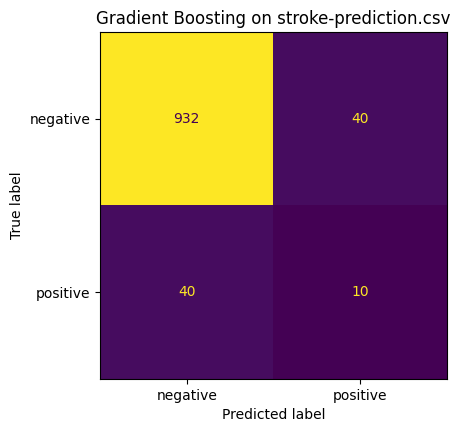

In [ ]:
THRESHOLD = 0.2 #chosen badsed on the above results
pipe.fit(X_train, y_train)

# predictions using the selected threshold
proba = pipe.predict_proba(X_test)[:, 1]
pred = (proba >= THRESHOLD).astype(int)

# Accuracy compared with the majority-classs baseline
majority = y_test.value_counts(normalize=True).max()   # share of the most common class in y_test (Tutorial 1, section 5)

print("accuracy {:.1%}, against {:.1%} for always predicting the commonest class".format(
    accuracy_score(y_test, pred), majority))

# Classification report
print(classification_report(y_test, pred, zero_division=0))   # recall: the share of each class caught


print("test set at threshold {}: precision {:.3f}, recall {:.3f}".format(
    THRESHOLD, precision_score(y_test, pred, zero_division=0), recall_score(y_test, pred)))

# Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, ax=ax, colorbar=False, display_labels=["negative", "positive"]
)

ax.set_title("Gradient Boosting on " + MY_FILE)
plt.show()

### Hyperparameter tuning (GridSearchCV)  

In [ ]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(pipe, {"model__n_estimators": [30, 100, 1000],
                             "model__learning_rate": [0.001, 0.01, 0.1],
                             "model__max_depth": [1, 2, 3]
                             },
                             cv=cv, scoring="roc_auc", return_train_score=True)

search.fit(X_train, y_train)

print("best parameters:", search.best_params_)
print("Best CV ROC AUC:", search.best_score_)

best parameters: {'model__learning_rate': 0.01, 'model__max_depth': 2, 'model__n_estimators': 1000}
Best CV ROC AUC: 0.8555896585234631


### GridSearchCV Results

In [ ]:
r = pd.DataFrame(search.cv_results_)

print("best n_estimators:", search.best_params_["model__n_estimators"])
print("best learning rate:", search.best_params_["model__learning_rate"])
print("best max depth:", search.best_params_["model__max_depth"])

pd.DataFrame({
    "model__n_estimators": r["param_model__n_estimators"],
    "model__learning_rate": r["param_model__learning_rate"],
    "model__max_depth": r["param_model__max_depth"],
    "training ROC AUC": r["mean_train_score"],
    "validation ROC AUC": r["mean_test_score"],
    "validation ROC AUC spread": r["std_test_score"]
}).sort_values("validation ROC AUC", ascending= False).round({"training ROC AUC": 4,
          "validation ROC AUC": 4,
          "validation ROC AUC spread": 4
          })

best n_estimators: 1000
best learning rate: 0.01
best max depth: 2


,model__n_estimators,model__learning_rate,model__max_depth,training ROC AUC,validation ROC AUC,validation ROC AUC spread
14,1000,0.010,2,0.9096,0.8556,0.0210
24,30,0.100,3,0.9107,0.8542,0.0228
22,100,0.100,2,0.9116,0.8541,0.0208
20,1000,0.100,1,0.8987,0.8519,0.0240
8,1000,0.001,3,0.8846,0.8513,0.0289
11,1000,0.010,1,0.8701,0.8512,0.0300
19,100,0.100,1,0.8704,0.8511,0.0311
16,100,0.010,3,0.8845,0.8510,0.0288
17,1000,0.010,3,0.9500,0.8503,0.0219
21,30,0.100,2,0.8788,0.8499,0.0254


### Final Model Selection

In [ ]:
### Final Model Selection: Record the selected hyperparameters and explain why they were selected.

### Final Evaluation  

In [ ]:
#### Final Evaluation: Evaluate the selected model using the agreed held-out test evaluation methodology.

### CONCLUSION

Test